# 03 — K-Nearest Neighbours and Support Vector Machine
**Member 3.** Implement and tune KNN and SVM on all 30 standardised features using
the common protocol. The test set is not used here.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from common import *
from models import build_pipeline, display_name, GRIDS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
del X_test, y_test

## 1. KNN
Grid: number of neighbours *k* (odd values 1–31, to avoid ties), uniform vs
distance weighting, and Euclidean vs Manhattan distance.
Standardisation is essential for KNN — without it `area_*` (values in the
thousands) would dominate every distance. The cell below shows this directly.

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
summarize([
    cv_evaluate(Pipeline([("clf", KNeighborsClassifier())]), X_train, y_train, name="KNN k=5, NOT scaled"),
    cv_evaluate(build_pipeline("knn"), X_train, y_train, name="KNN k=5, standardised"),
])

,model,accuracy,precision,recall,specificity,f1,roc_auc
0,"KNN k=5, NOT scaled",0.9341 ± 0.0287,0.9390 ± 0.0503,0.8824 ± 0.0416,0.9649 ± 0.0294,0.9092 ± 0.0394,0.9589 ± 0.0156
1,"KNN k=5, standardised",0.9648 ± 0.0189,0.9875 ± 0.0250,0.9176 ± 0.0343,0.9930 ± 0.0140,0.9510 ± 0.0263,0.9871 ± 0.0136


In [3]:
knn_grid = GRIDS["knn"]
print(knn_grid)
knn_gs = tune(build_pipeline("knn"), knn_grid, X_train, y_train)
print("best params:", knn_gs.best_params_)
print(f"best CV F1: {knn_gs.best_score_:.4f}")

{'clf__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31], 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}


best params: {'clf__n_neighbors': 3, 'clf__p': 1, 'clf__weights': 'uniform'}
best CV F1: 0.9667


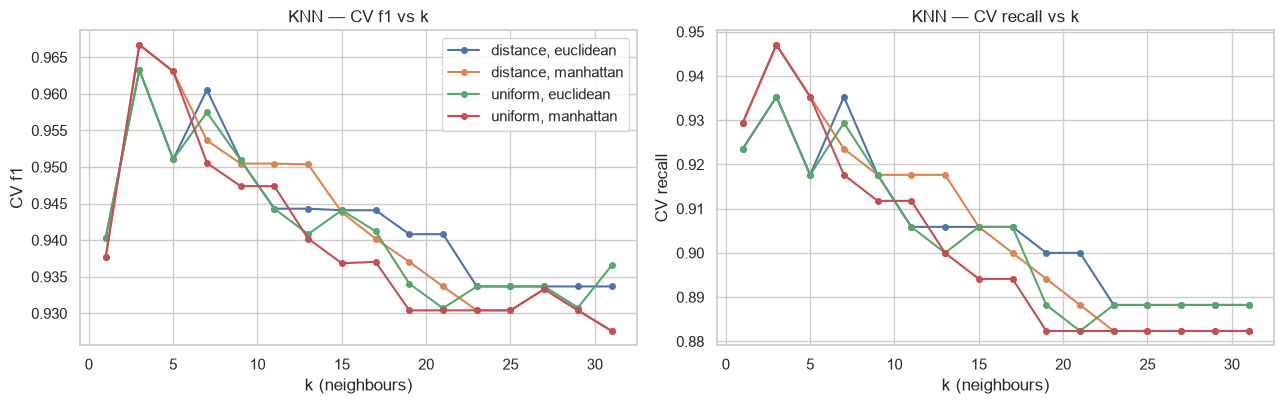

In [4]:
r = pd.DataFrame(knn_gs.cv_results_)
r["config"] = r["param_clf__weights"] + ", " + r["param_clf__p"].map({1: "manhattan", 2: "euclidean"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, metric in zip(axes, ["f1", "recall"]):
    for cfg, g in r.groupby("config"):
        ax.plot(g["param_clf__n_neighbors"], g[f"mean_test_{metric}"], "o-", ms=4, label=cfg)
    ax.set_xlabel("k (neighbours)"); ax.set_ylabel(f"CV {metric}"); ax.set_title(f"KNN — CV {metric} vs k")
axes[0].legend(); fig.tight_layout(); savefig(fig, "03_knn_k_curve"); plt.show()

The best *k* is small (k = 3 with Manhattan distance). k = 1 overfits (it memorises the
training fold), and from k ≈ 5 upwards performance declines steadily. The drop shows
up mostly in **recall**: as the neighbourhood grows, the minority (malignant) class gets
outvoted near the boundary.

## 2. SVM
Grid: linear and RBF kernels, `C` (margin softness), `gamma` (RBF width) and
`class_weight`.

In [5]:
svm_grid = GRIDS["svm"]
svm_gs = tune(build_pipeline("svm"), svm_grid, X_train, y_train)
print("best params:", svm_gs.best_params_)
print(f"best CV F1: {svm_gs.best_score_:.4f}")

best params: {'clf__C': np.float64(3.1622776601683795), 'clf__class_weight': 'balanced', 'clf__gamma': np.float64(0.01), 'clf__kernel': 'rbf'}
best CV F1: 0.9760


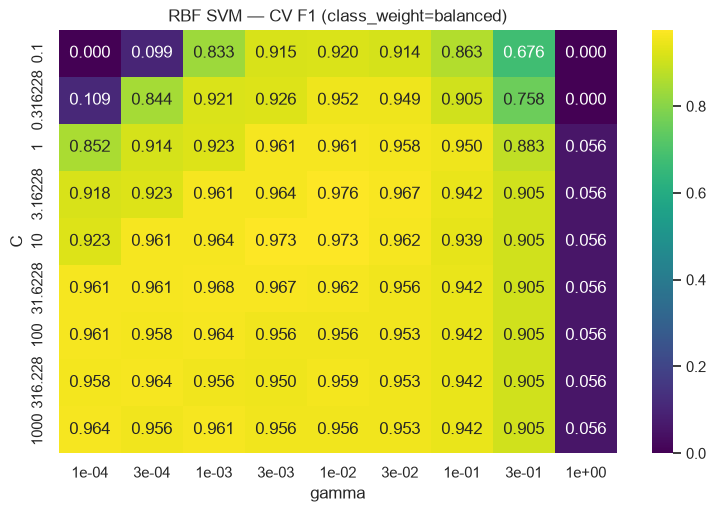

In [6]:
r = pd.DataFrame(svm_gs.cv_results_)
rbf = r[(r["param_clf__kernel"] == "rbf")]
cw_best = svm_gs.best_params_["clf__class_weight"]
rbf = rbf[rbf["param_clf__class_weight"].astype(str) == str(cw_best)]
heat = rbf.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_f1")
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=ax,
            xticklabels=[f"{g:.0e}" for g in heat.columns], yticklabels=[f"{c:g}" for c in heat.index])
ax.set_xlabel("gamma"); ax.set_ylabel("C")
ax.set_title(f"RBF SVM — CV F1 (class_weight={cw_best})")
savefig(fig, "03_svm_rbf_heatmap"); plt.show()

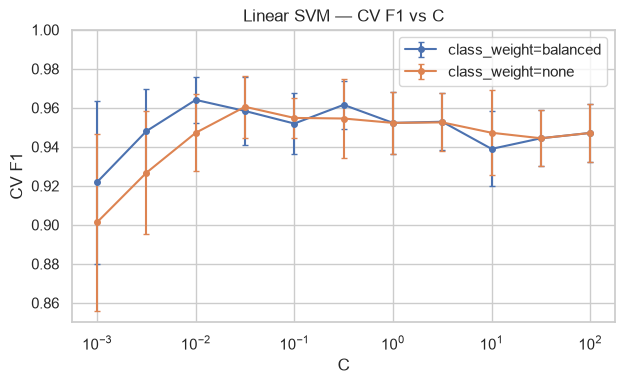

In [7]:
lin = r[r["param_clf__kernel"] == "linear"].copy()
lin["cw"] = lin["param_clf__class_weight"].fillna("none")
fig, ax = plt.subplots(figsize=(7, 3.8))
for cw, g in lin.groupby("cw"):
    ax.errorbar(g["param_clf__C"].astype(float), g["mean_test_f1"], yerr=g["std_test_f1"], marker="o", ms=4,
                capsize=2, label=f"class_weight={cw}")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("CV F1"); ax.set_ylim(0.85, 1); ax.legend()
ax.set_title("Linear SVM — CV F1 vs C")
savefig(fig, "03_svm_linear_C"); plt.show()

### Best linear vs best RBF kernel

In [8]:
rows = []
for kern in ["linear", "rbf"]:
    sub = r[r["param_clf__kernel"] == kern]
    i = sub["mean_test_f1"].idxmax()
    row = {"model": f"SVM ({kern})", "params": {k.replace("clf__", ""): v for k, v in r.loc[i, "params"].items()}}
    for m in METRICS:
        row[f"cv_{m}"] = r.loc[i, f"mean_test_{m}"]; row[f"cv_{m}_std"] = r.loc[i, f"std_test_{m}"]
    rows.append(row)
summarize(rows)

,model,params,accuracy,precision,recall,specificity,f1,roc_auc
0,SVM (linear),"{'C': 0.01, 'class_weight': 'balanced', 'kerne...",0.9736 ± 0.0088,0.9825 ± 0.0230,0.9471 ± 0.0220,0.9895 ± 0.0140,0.9641 ± 0.0119,0.9928 ± 0.0073
1,SVM (rbf),"{'C': 3.1622776601683795, 'class_weight': 'bal...",0.9824 ± 0.0112,0.9889 ± 0.0222,0.9647 ± 0.0343,0.9930 ± 0.0140,0.9760 ± 0.0156,0.9951 ± 0.0060


## 3. Comparison

In [9]:
rows = [best_cv_row(knn_gs, display_name("knn"), key="knn", feature_set="all 30"),
        best_cv_row(svm_gs, display_name("svm"), key="svm", feature_set="all 30")]
save_rows(rows, "cv_03_knn_svm.csv")
save_best_params("knn", knn_gs.best_params_)
save_best_params("svm", svm_gs.best_params_)
summarize(rows)

,model,key,feature_set,accuracy,precision,recall,specificity,f1,roc_auc
0,KNN,knn,all 30,0.9758 ± 0.0162,0.9877 ± 0.0151,0.9471 ± 0.0343,0.9930 ± 0.0086,0.9667 ± 0.0223,0.9834 ± 0.0102
1,SVM,svm,all 30,0.9824 ± 0.0112,0.9889 ± 0.0222,0.9647 ± 0.0343,0.9930 ± 0.0140,0.9760 ± 0.0156,0.9951 ± 0.0060


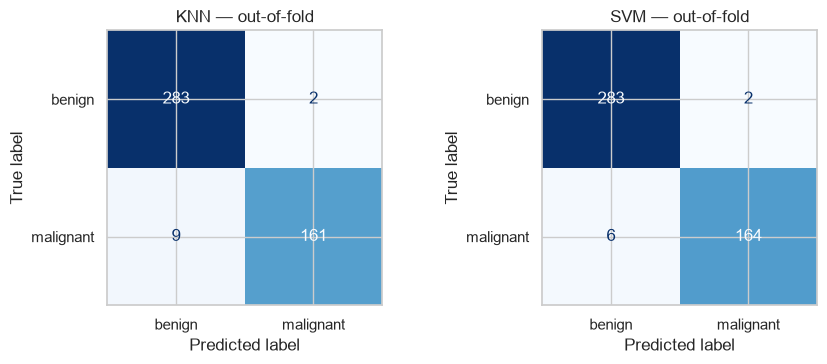

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
oof = {}
for ax, (key, gs) in zip(axes, [("knn", knn_gs), ("svm", svm_gs)]):
    oof[key] = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=get_cv())
    ConfusionMatrixDisplay.from_predictions(y_train, oof[key], display_labels=CLASS_NAMES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{display_name(key)} — out-of-fold")
fig.tight_layout(); savefig(fig, "03_confusion"); plt.show()

In [11]:
err = pd.DataFrame({"true": y_train, "knn": oof["knn"], "svm": oof["svm"]})
print("errors — KNN:", int((err.true != err.knn).sum()), " SVM:", int((err.true != err.svm).sum()),
      " both:", int(((err.true != err.knn) & (err.true != err.svm)).sum()))
print("KNN false negatives (missed malignant):", int(((err.true == 1) & (err.knn == 0)).sum()))
print("SVM false negatives (missed malignant):", int(((err.true == 1) & (err.svm == 0)).sum()))

errors — KNN: 11  SVM: 8  both: 4
KNN false negatives (missed malignant): 9
SVM false negatives (missed malignant): 6
